# KDD Project: Finding Grocery Products Purchased Together

**Student:** Arti Ramesh Nalawade  
**Student ID:** 020757113

## What is this project about?
Imagine you manage a grocery store. You want to know which items customers buy together, so you can plan shelves, bundles, or suggestions. We will analyze real shopping records from Kaggle and follow the five stages of KDD (Knowledge Discovery in Databases).

**How to run:** Open in Google Colab and choose Runtime > Run all. The notebook downloads the Kaggle Groceries Dataset. Confirm that the printed source starts with `Kaggle:`. If it says fallback, do not use that run as your final Kaggle result.

**How to read:** Each stage explains what we are doing, why it matters, and what the results mean. The final output is a CSV of shopping patterns and a simple manual check.


## Stage 1: Selection + problem understanding
Select customer-item transactions. Each receipt is a basket. We are searching for product associations, not claiming that buying one item causes another.


In [1]:
!pip -q install kagglehub mlxtend joblib


In [2]:
import os,glob,warnings
import pandas as pd,numpy as np,matplotlib.pyplot as plt
from IPython.display import display
DATA_SOURCE='Kaggle: heeraldedhia/groceries-dataset'
try:
 import kagglehub
 p=kagglehub.dataset_download('heeraldedhia/groceries-dataset')
 files=glob.glob(os.path.join(p,'**','*.csv'),recursive=True)
 assert files,'No CSV in Kaggle download'
 df=pd.read_csv(files[0]);print('Downloaded fields:',df.columns.tolist())
except Exception as e:
 warnings.warn('KAGGLE DOWNLOAD FAILED: using synthetic teaching data; does NOT satisfy dataset requirement. '+str(e)[:150])
 rng=np.random.default_rng(42)
 baskets=[]
 for ix in range(1200):
  items=['milk'] if rng.random()<.45 else []
  if rng.random()<.6:items.append('bread')
  if 'bread' in items and rng.random()<.65:items.append('butter')
  if rng.random()<.28:items.append('eggs')
  if rng.random()<.25:items.append('apples')
  if not items:items=['bananas']
  baskets.extend([{'Member_number':ix,'Date':'2026-01-01','itemDescription':it} for it in set(items)])
 df=pd.DataFrame(baskets)
 DATA_SOURCE='FALLBACK ONLY: synthetic baskets'
print('SOURCE:',DATA_SOURCE,'Shape:',df.shape);display(df.head())


100%|██████████| 257k/257k [00:00<00:00, 52.5MB/s]

Extracting files...
Downloaded fields: ['Member_number', 'Date', 'itemDescription']
SOURCE: Kaggle: heeraldedhia/groceries-dataset Shape: (38765, 3)


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


## Stage 2: Preprocessing - inspect errors and clean records
The public groceries data lists products purchased by members on dates. A basket is one member on one date. A member may shop on multiple days, so combining all their purchases would be a mistake.


In [3]:
df.columns=[str(x).strip() for x in df.columns]
lookup={x.lower():x for x in df.columns}
assert 'itemdescription' in lookup and 'member_number' in lookup and 'date' in lookup, 'Expected groceries dataset columns not found; inspect downloaded file.'
item,member,date=[lookup[x] for x in ['itemdescription','member_number','date']]
work=df[[item,member,date]].copy()
print('Nulls:',work.isna().sum().to_dict(),'duplicates:',int(work.duplicated().sum()))
work=work.dropna().drop_duplicates()
work[item]=work[item].astype(str).str.strip().str.lower()
work=work[work[item].ne('')]
work['basket_id']=work[member].astype(str)+'|'+work[date].astype(str)
print('Unique baskets:',work['basket_id'].nunique(),'Unique products:',work[item].nunique())
assert work['basket_id'].nunique()>50


Nulls: {'itemDescription': 0, 'Member_number': 0, 'Date': 0} duplicates: 759
Unique baskets: 14963 Unique products: 167


## Stage 3: Transformation - create transaction-by-product table
Each row is a basket. A `True` in a product column means the product appears in that basket. This is the input format for Apriori.


Baskets x selected products: (14963, 35)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,fraction_of_baskets
itemDescription,
whole milk,0.157923
other vegetables,0.122101
rolls/buns,0.110005
soda,0.097106
yogurt,0.085879
root vegetables,0.069572
tropical fruit,0.067767
bottled water,0.060683
sausage,0.060349


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

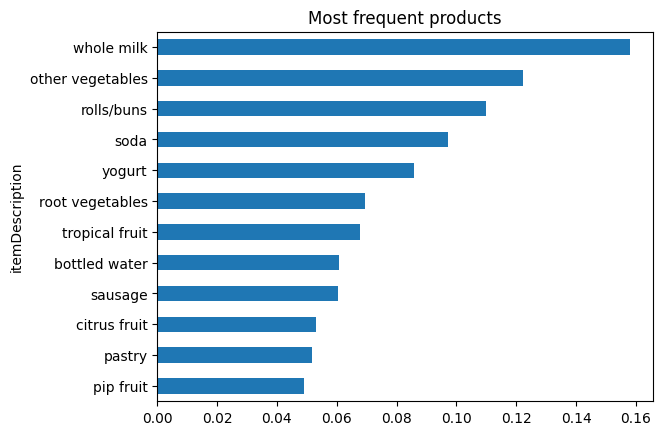

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [4]:
from mlxtend.frequent_patterns import apriori,association_rules
basket=pd.crosstab(work['basket_id'],work[item]).gt(0)
# Restrict to common products so the public Colab demo stays quick; record this deliberate choice.
common=basket.mean().sort_values(ascending=False)
selected_items=common.head(35).index
basket=basket[selected_items]
print('Baskets x selected products:',basket.shape)
display(common.head(12).rename('fraction_of_baskets'))
common.head(12).sort_values().plot.barh(title='Most frequent products');plt.show()


## Stage 4: Data mining - discover combinations with Apriori

Apriori finds groups of products that appear together often enough. For example, a group containing milk and vegetables means some customers bought both in the same shopping visit.

- **Support:** Out of all baskets, how many contain the item combination? Support of 0.01 means about 1 in 100 baskets.
- **Confidence:** Among baskets containing product A, what fraction also contain B?
- **Lift:** How strongly A and B occur together compared with what we would expect from their separate popularity. Lift above 1 suggests a positive association, but does not prove one purchase causes another.

### Why we revised this section
In the first run, minimum support was 0.015 (1.5%). That returned 35 one-product itemsets, but no rules. This was too strict to show useful product pairs. We now try **0.005 (0.5%)**, meaning at least about 75 of 14,963 baskets must contain a pair. We keep the top 35 products to make Colab run quickly. This restriction may miss less popular products, so our conclusions apply only to these selected products.

We show rules with confidence at least 0.05 (5%) and lift above 1. The thresholds are exploration choices, not universal standards. Any suggested promotion would need real-world testing.


In [5]:
# Compare the original strict threshold with the revised threshold.
original_freq = apriori(basket, min_support=0.015, use_colnames=True, max_len=3)
print('Original threshold 1.5% - itemsets:', len(original_freq),
      '| multi-product itemsets:', int((original_freq.itemsets.map(len) >= 2).sum()))

MIN_SUPPORT = 0.005
freq = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=3)
print('Revised threshold 0.5% - itemsets:', len(freq),
      '| multi-product itemsets:', int((freq.itemsets.map(len) >= 2).sum()))
display(freq.sort_values('support', ascending=False).head(12))

if (freq['itemsets'].map(len) >= 2).any():
    try:
        rules = association_rules(freq, num_itemsets=len(basket), metric='confidence', min_threshold=0.05)
    except TypeError:
        rules = association_rules(freq, metric='confidence', min_threshold=0.05)
    rules = rules.loc[(rules['lift'] > 1.0) & (rules['support'] >= MIN_SUPPORT)].copy()
    rules = rules.sort_values(['lift', 'support'], ascending=False)
else:
    rules = pd.DataFrame()

if not rules.empty:
    printable = rules.copy()
    for column in ['antecedents', 'consequents']:
        printable[column] = printable[column].map(lambda items: ', '.join(sorted(items)))
    print('Association rules found:', len(printable))
    display(printable[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(12))
else:
    print('No positive-lift rules met the chosen thresholds. This is a valid result; do not invent rules.')


Original threshold 1.5% - itemsets: 35 | multi-product itemsets: 0
Revised threshold 0.5% - itemsets: 72 | multi-product itemsets: 37


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
0,0.157923,(whole milk)
1,0.122101,(other vegetables)
2,0.110005,(rolls/buns)
3,0.097106,(soda)
4,0.085879,(yogurt)
5,0.069572,(root vegetables)
6,0.067767,(tropical fruit)
7,0.060683,(bottled water)
8,0.060349,(sausage)
9,0.053131,(citrus fruit)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Association rules found: 5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
35,frankfurter,other vegetables,0.005146,0.136283,1.116150
55,sausage,yogurt,0.005748,0.095238,1.108986
56,yogurt,sausage,0.005748,0.066926,1.108986
51,sausage,soda,0.005948,0.098560,1.014975
52,soda,sausage,0.005948,0.061253,1.014975


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Stage 5: Interpretation and evaluation - check the results ourselves

A computer can output a number, but we still need to check whether it makes sense.

We independently calculate support and confidence for the first discovered rule and compare the answers with Apriori. If no rules qualify, we independently check the support of the most common itemset instead.

**How a store might use these findings:** Inspect product pairs with useful support and confidence, consider whether they are realistic, and test a promotion on a small scale. A rule is not proof that a promotion will increase sales.

**Limitations:** We analyzed one public dataset and only the 35 most popular products. We have not tested whether the rules remain stable on future dates. Results are associations, not causes.


In [6]:
# Independently validate a pattern using basket data.
if not rules.empty:
    r = rules.iloc[0]
    A = list(r['antecedents'])
    B = list(r['consequents'])
    has_A = basket[A].all(axis=1)
    has_B = basket[B].all(axis=1)
    both = has_A & has_B
    manual_support = both.mean()
    manual_confidence = both.sum() / has_A.sum()
    assert np.isclose(manual_support, r['support'])
    assert np.isclose(manual_confidence, r['confidence'])
    print('Verified first rule:', ', '.join(A), '->', ', '.join(B))
    print('Manual support:', round(manual_support, 4), 'Manual confidence:', round(manual_confidence, 4))
else:
    top = freq.sort_values('support', ascending=False).iloc[0]
    cols = list(top['itemsets'])
    manual_support = basket[cols].all(axis=1).mean()
    assert np.isclose(manual_support, top['support'])
    print('No rules qualified. Verified top itemset support:', round(manual_support, 4))

os.makedirs('artifacts', exist_ok=True)
freq.assign(itemsets=freq.itemsets.map(lambda v: ', '.join(sorted(v)))).to_csv('artifacts/frequent_itemsets.csv', index=False)
if not rules.empty:
    printable.to_csv('artifacts/association_rules.csv', index=False)
else:
    pd.DataFrame(columns=['antecedents', 'consequents', 'support', 'confidence', 'lift']).to_csv('artifacts/association_rules.csv', index=False)
print('Saved artifacts/frequent_itemsets.csv and artifacts/association_rules.csv')


Verified first rule: frankfurter -> other vegetables
Manual support: 0.0051 Manual confidence: 0.1363
Saved artifacts/frequent_itemsets.csv and artifacts/association_rules.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## AI critique and revision record

**Critique round 1 - review of the executed original notebook (November 2, 2026)**

- **Issue:** Apriori minimum support of 1.5% returned only single-product itemsets and no association rules, limiting the ability to explain combinations.
- **Revision:** Lowered the threshold to 0.5%, explained why, and printed the before and after itemset counts.
- **Issue:** A strong-sounding product relationship should not be trusted without a check.
- **Revision:** Added independent support and confidence calculations with assertions.
- **Issue:** Working only with the most popular 35 products could overlook other combinations.
- **Revision:** Explicitly explained this limitation, rather than claiming we analyzed every product relationship.

**Verification required:** Run this revised notebook in Colab and inspect the actual rule counts and final outputs. Record any further fixes if the results reveal new issues. Do not claim this notebook found rules until it has been executed.

## Practical handoff

The notebook creates `frequent_itemsets.csv` and `association_rules.csv`. A store analyst could review these findings as hypotheses before testing any offer or promotion.


In [7]:
import shutil
shutil.make_archive('KDD_artifacts','zip','artifacts')
print('Download KDD_artifacts.zip in Colab Files sidebar')


Download KDD_artifacts.zip in Colab Files sidebar


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag